# Load initial

In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
GTE_DIR=os.environ["GTE_DIR"]
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
from glaciation_time_estimator.auxiliary_func.Helper_fun import float_range
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import cmcrameri.cm
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader
import datetime as dt

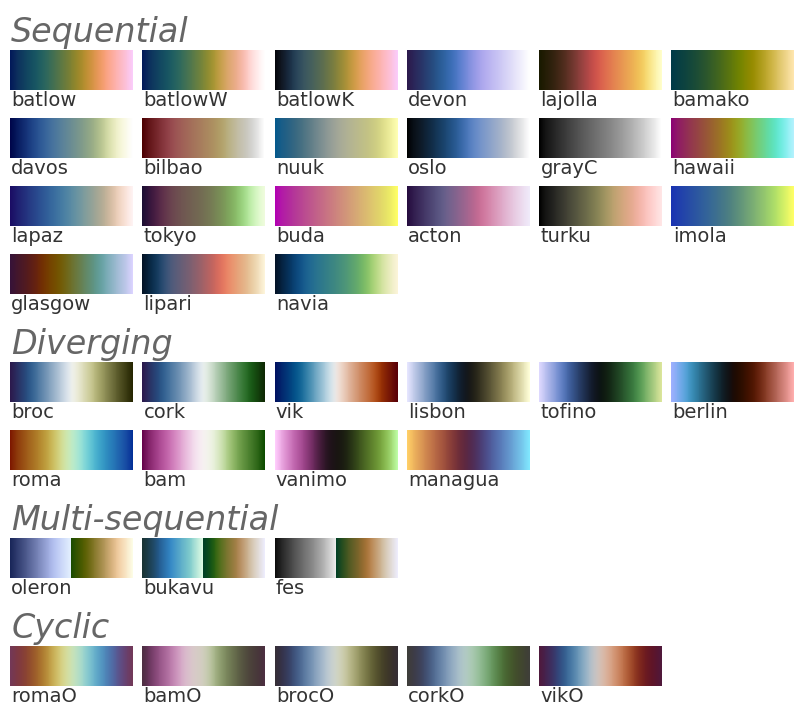

In [2]:
cmcrameri.cm.show_cmaps()

In [3]:
colormap = cmcrameri.cm.lipariS

In [4]:
color_low_res = colormap(0)
color_high_res = colormap(4)
color_model_old_wbf = colormap(3)
color_model_new_wbf = colormap(2)

In [5]:
glac_threshold=0.4
def calculate_pole_temp_occurance_rate(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk,values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')
def calculate_pole_temp_occurance_rate_glac_possible(dfs):
    cloud_chunk , _ , _ = dfs
    return pd.pivot_table(cloud_chunk[cloud_chunk.max_water_frac > glac_threshold],values='is_glaciating' ,index=["Hemisphere"], columns=["min_temp"], aggfunc='mean')


# 1 Load data

CLAAS data (1 degree)

In [6]:
# glac_low_res_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080901.0000_20080914.2345.parquet")
# glac_low_res_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_Glaciations_20080915.0000_20080930.2345.parquet")
# glac_low_res = pd.concat([glac_low_res_01,glac_low_res_02],axis=0,ignore_index=True)
# clouds_low_res_01 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080901.0000_20080914.2345.parquet")
# clouds_low_res_02 = pd.read_parquet("/wolke_scratch/dnikolo/dump/regrided_data/Results/Agg_20_clouds_20080915.0000_20080930.2345.parquet")
# clouds_low_res = pd.concat([clouds_low_res_01,clouds_low_res_02],axis=0,ignore_index=True)


CLAAS data (original - 0.15)

In [42]:
# config_claas_low_res = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/Low_resolution_tests/Agg_30/config_n2o.yaml")
config_claas_low_res = read_config("/cluster/work/climate/dnikolo/n2o/Glaciation_time_estimator/configs/Low_resolution_tests/Agg_30/2007_tracking/01_01.yaml")
loader_claas_low_res = ChunkLoader([2007],config_claas_low_res,filter=True)


Cloud_fps: {2007: '/nfs/ch4/wolke_scratch/dnikolo/GTE_Results/Low_resolution/Final_results/2007_all.parquet'}


In [43]:
# config_claas_high_res = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/config_n2o.yaml")
config_claas_high_res = read_config("/cluster/work/climate/dnikolo/n2o/Glaciation_time_estimator/configs/config_euler.yaml")
loader_claas_high_res = ChunkLoader([2007],config_claas_high_res,filter=True)

Cloud_fps: {2007: '/nfs/ch4/wolke_scratch/dnikolo/GTE_Results/Final_results/2007_all.parquet'}


In [6]:
# config_icon = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/ICON_output/wbf_v1_ndg_1y/read_n2o.yaml")
# config_icon = read_config("/nfs/ch4/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/ICON_output/nudged_3y/2007_tracking/01_01.yaml")
config_icon = read_config("/cluster/work/climate/dnikolo/n2o/Glaciation_time_estimator/configs/ICON_output/no_nudging/R2B4/wbf_v1/template.yaml")
# config_icon = read_config("/cluster/work/climate/dnikolo/n2o/Glaciation_time_estimator/configs/ICON_output/nudged_3y/12_02_testing.yaml")
loader_icon = ChunkLoader([2007],config_icon,filter=True)
# clouds_model= pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/Pre_rerun_results/nudged_3y/postprocessing_output/Results/Agg_03_clouds_20071215.0000_20071231.2345.parquet")
# glac_model = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/Pre_rerun_results/nudged_3y/postprocessing_output/Results/Agg_03_glaciations_20071215.0000_20071231.2345.parquet")
# clouds_model= pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/debug_no_ndg_v1/postprocessing_output/Results/Agg_03_clouds_20071215.0000_20071231.2345.parquet")
# glac_model = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/debug_no_ndg_v1/postprocessing_output/Results/Agg_03_glaciations_20071215.0000_20071231.2345.parquet")
# clouds_model= pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/debug_fwbf_00_v3/postprocessing_output/Results/Agg_03_clouds_20070115.0000_20070131.2345.parquet")
# glac_model = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/debug_fwbf_00_v3/postprocessing_output/Results/Agg_03_glaciations_20070115.0000_20070131.2345.parquet")

Cloud_fps: {2007: '/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/wbf_v1/postprocessing_output/Final_results/2007_all.parquet'}


In [7]:
# config_icon_new_wbf = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/ICON_output/wbf_v3_ndg_1y/read_n2o.yaml")
# config_icon_new_wbf = read_config("/nfs/ch4/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/ICON_output/nudged_wbf_v2_1y/2007_tracking/01_01.yaml")
config_icon_new_wbf = read_config("/cluster/work/climate/dnikolo/n2o/Glaciation_time_estimator/configs/ICON_output/no_nudging/R2B4/wbf_v3/template.yaml")
loader_icon_new_wbf = ChunkLoader([2007],config_icon_new_wbf,filter=True)

# clouds_model_new_wbf = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/Pre_rerun_results/nudged_wbf_v2_1y/postprocessing_output/Results/Agg_03_clouds_20071215.0000_20071231.2345.parquet")
# glac_model_new_wbf = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/Pre_rerun_results/nudged_wbf_v2_1y/postprocessing_output/Results/Agg_03_glaciations_20071215.0000_20071231.2345.parquet")
# clouds_model_new_wbf= pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/debug_no_ndg_v3/postprocessing_output/Results/Agg_03_clouds_20071215.0000_20071231.2345.parquet")
# glac_model_new_wbf = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/debug_no_ndg_v3/postprocessing_output/Results/Agg_03_glaciations_20071215.0000_20071231.2345.parquet")
# clouds_model_new_wbf= pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/debug_fwbf_05_v3/postprocessing_output/Results/Agg_03_clouds_20070115.0000_20070131.2345.parquet")
# glac_model_new_wbf = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/debug_fwbf_05_v3/postprocessing_output/Results/Agg_03_glaciations_20070115.0000_20070131.2345.parquet")

Cloud_fps: {2007: '/nfs/ch4/wolke_scratch/dnikolo/ICON_Data/no_nudging/R2B4/wbf_v3/postprocessing_output/Final_results/2007_all.parquet'}


Model 160 km

In [44]:
clouds_high_res = loader_claas_high_res.cloud_chunk
glac_high_res = loader_claas_high_res.glac_chunk
clouds_low_res = loader_claas_low_res.cloud_chunk
glac_low_res = loader_claas_low_res.glac_chunk
clouds_model = loader_icon.cloud_chunk
glac_model = loader_icon.glac_chunk
clouds_model_new_wbf = loader_icon_new_wbf.cloud_chunk
glac_model_new_wbf = loader_icon_new_wbf.glac_chunk

In [45]:
glac_model_new_wbf.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km', 'min_temp',
       'max_temp', 'pole', 'Hemisphere', 'Lifetime [h]', 'Radius [km]',
       'Level', 'Optical Thickness', 'Cloud type', 'Season', 'Peak IF'],
  

clouds_model.sample(10000,random_state=1).equals(clouds_model_new_wbf.sample(10000,random_state=1))

In [46]:
start_time=pd.Timestamp("2008-09-01")
end_time= pd.Timestamp("2008-09-08")
def time_filter(df):
    return df[(df.track_start_time>=start_time) & (df.track_start_time<end_time)]
def get_peak_if(glac_df_row):
    return glac_df_row["ice_frac_hist"][glac_df_row["Glac_peak_ind"]]
def set_peak_if(glac_df):
    glac_df["Peak IF"] = glac_df.apply(get_peak_if,axis=1)
def filter_df(df):
    return df[(~df.is_large_pix_cloud) & (abs(df.avg_lat)>30)]
def preproc_glac(glac_df):
    set_peak_if(glac_df)
    return filter_df(time_filter(glac_df))
def preproc_cloud(cloud_df):
    return filter_df(time_filter(cloud_df))

set_peak_if(glac_high_res)
set_peak_if(glac_low_res)
set_peak_if(glac_model)
set_peak_if(glac_model_new_wbf)

# clouds_high_res = clouds_high_res[clouds_high_res["avg_size[km]"]>3e4]

In [11]:
len(glac_model_new_wbf.iloc[0]["ice_frac_hist"])

43

In [22]:
# Dict values are timedeltas
vals_instant = np.array(list(glac_model.track_length.values))

# Convert timedeltas to minutes
minutes_instant = vals_instant.astype("timedelta64[s]").astype(float) / 60

# Dict values are timedeltas
vals_rl = np.array(list(glac_model_new_wbf.track_length.values))

# Convert timedeltas to minutes
minutes_rl = vals_rl.astype("timedelta64[s]").astype(float) / 60

In [25]:
minutes_rl.mean()

304.7774204286757

In [26]:
minutes_instant.mean()

285.5219268306182

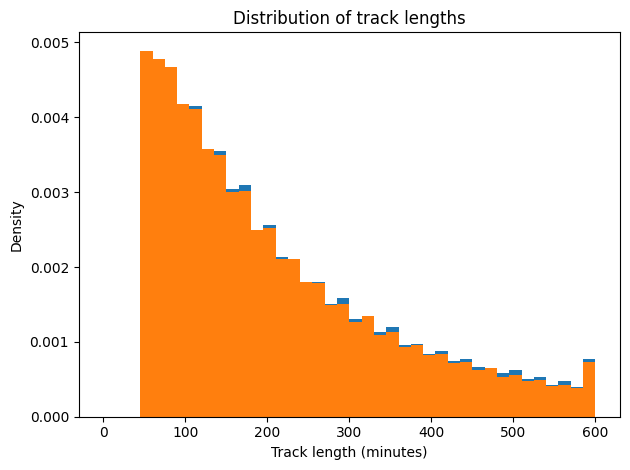

In [24]:
plt.hist(minutes_rl, bins=40,range=[0,600],density=True)
plt.hist(minutes_instant, bins=40,range=[0,600],density=True)
plt.xlabel("Track length (minutes)")
plt.ylabel("Density")
plt.title("Distribution of track lengths")
plt.tight_layout()
plt.show()

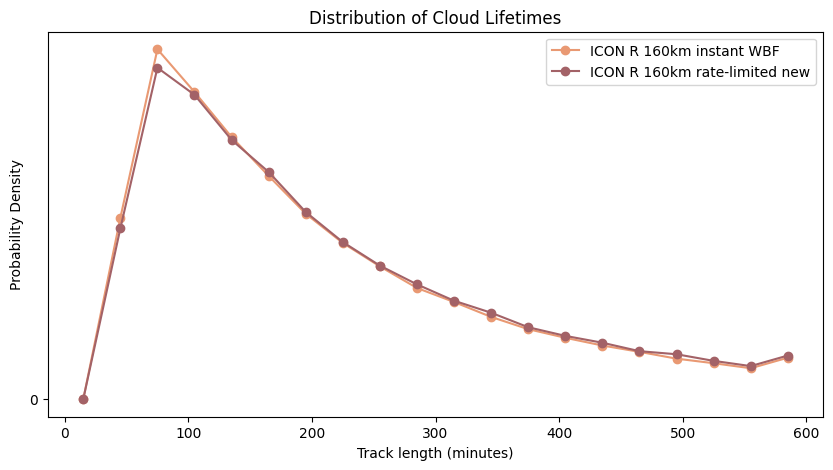

In [32]:
fig, ax = plt.subplots(figsize=(10, 5))

# Transparent background
fig.patch.set_alpha(0)
ax.set_facecolor("none")

bins = 20
hist_range = [0, 600]

# ICON instant WBF
vals_instant = np.array(list(glac_model.track_length.values))
minutes_instant = vals_instant.astype("timedelta64[s]").astype(float) / 60

counts1, edges1 = np.histogram(
    minutes_instant[~np.isnan(minutes_instant)],
    bins=bins,
    range=hist_range,
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])

ax.plot(
    centers1,
    counts1,
    "-o",
    label="ICON R 160km instant WBF",
    color=color_model_old_wbf
)

# ICON rate-limited new WBF
vals_rl = np.array(list(glac_model_new_wbf.track_length.values))
minutes_rl = vals_rl.astype("timedelta64[s]").astype(float) / 60

counts2, edges2 = np.histogram(
    minutes_rl[~np.isnan(minutes_rl)],
    bins=bins,
    range=hist_range,
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])

ax.plot(
    centers2,
    counts2,
    "-o",
    label="ICON R 160km rate-limited new",
    color=color_model_new_wbf
)

ax.set_title("Distribution of Cloud Lifetimes")
ax.set_xlabel("Track length (minutes)")
ax.set_ylabel("Probability Density")

# Keep only 0 on the vertical axis
ax.set_yticks([0])
ax.tick_params(axis="y", left=True, right=False, labelleft=True)


ax.legend()

# plt.savefig(
#     "track_length_distribution.png",
#     transparent=True,
#     bbox_inches="tight",
#     dpi=300
# )

plt.show()

In [38]:
len(glac_model)

271015

In [41]:
len(glac_model_new_wbf)/len(glac_model)

0.6872239543936682

In [39]:
len(glac_model_new_wbf)

186248

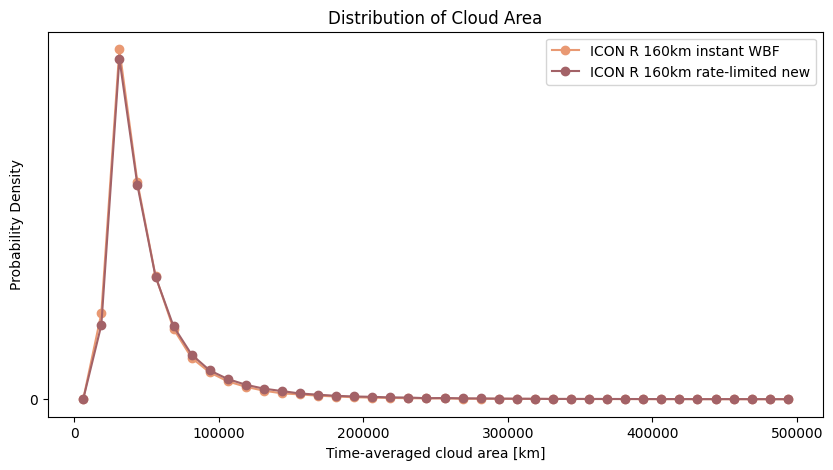

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))

# Transparent background
fig.patch.set_alpha(0)
ax.set_facecolor("none")

bins = 40
hist_range = [0, 5e5]  # adjust if your cloud areas extend beyond this

# ICON instant WBF
area_instant = glac_model["avg_size[km]"].dropna().to_numpy()

counts1, edges1 = np.histogram(
    area_instant,
    bins=bins,
    range=hist_range,
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])

ax.plot(
    centers1,
    counts1,
    "-o",
    label="ICON R 160km instant WBF",
    color=color_model_old_wbf
)

# ICON rate-limited new WBF
area_rl = glac_model_new_wbf["avg_size[km]"].dropna().to_numpy()

counts2, edges2 = np.histogram(
    area_rl,
    bins=bins,
    range=hist_range,
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])

ax.plot(
    centers2,
    counts2,
    "-o",
    label="ICON R 160km rate-limited new",
    color=color_model_new_wbf
)

ax.set_title("Distribution of Cloud Area")
ax.set_xlabel("Time-averaged cloud area [km]")
ax.set_ylabel("Probability Density")

# Keep only 0 on the vertical axis
ax.set_yticks([0])
ax.tick_params(axis="y", left=True, right=False, labelleft=True)

ax.legend()

plt.savefig(
    "avg_cloud_area_distribution.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300
)

plt.show()

In [13]:
# def set_is_glaciating(cloud_df,glac_df):
#     cloud_df['is_glaciating'] = (
#                     cloud_df.index.isin(
#                         glac_df['Cloud_ID']
#                     )
#                 )

# set_is_glaciating(clouds_low_res,glac_low_res)
# set_is_glaciating(clouds_model_offline,glac_model_offline)
# set_is_glaciating(clouds_model,glac_model)


In [14]:
# def set_hemisphere(cloud_df):
#     cloud_df['Hemisphere'] = np.where(cloud_df['avg_lat']>=0,'North','South')
# set_hemisphere(clouds_model_offline)
# set_hemisphere(clouds_model)

# Plots

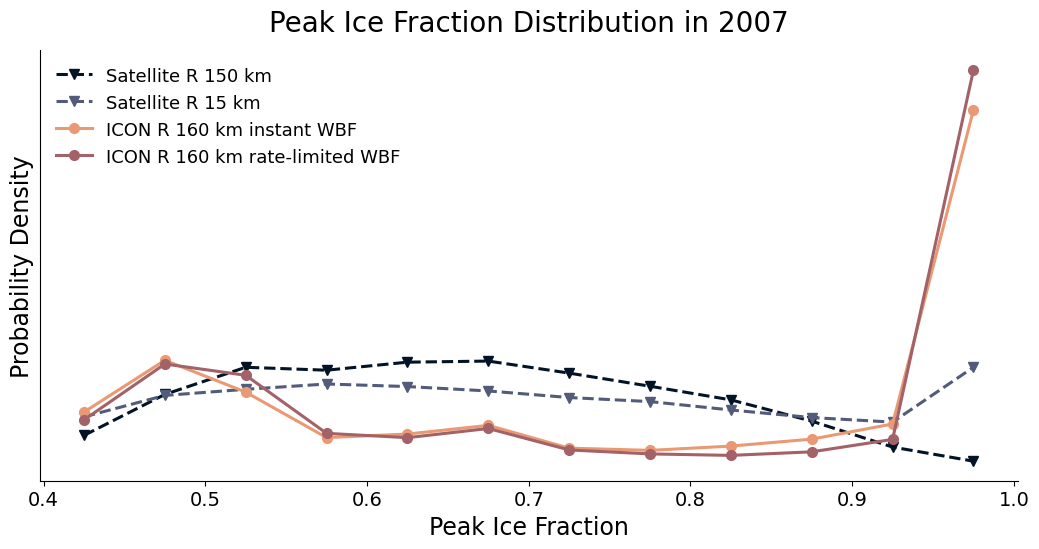

In [15]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
fig.patch.set_alpha(0)
ax.set_facecolor("none")

bins = 12

# CLAAS
counts1, edges1 = np.histogram(
    glac_low_res["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(
    centers1, counts1,
    "--v",
    label="Satellite R 150 km",
    color=color_low_res,
    linewidth=2.2,
    markersize=7
)

# GLAC High Res
counts3, edges3 = np.histogram(
    glac_high_res["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(
    centers3, counts3,
    "--v",
    label="Satellite R 15 km",
    color=color_high_res,
    linewidth=2.2,
    markersize=7
)

# ICON
counts2, edges2 = np.histogram(
    glac_model["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(
    centers2, counts2,
    "-o",
    label="ICON R 160 km instant WBF",
    color=color_model_old_wbf,
    linewidth=2.2,
    markersize=7
)

# ICON new WBF
counts4, edges4 = np.histogram(
    glac_model_new_wbf["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers4 = 0.5 * (edges4[:-1] + edges4[1:])
ax.plot(
    centers4, counts4,
    "-o",
    label="ICON R 160 km rate-limited WBF",
    color=color_model_new_wbf,
    linewidth=2.2,
    markersize=7
)

ax.set_title(
    "Peak Ice Fraction Distribution in 2007",
    fontsize=20,
    pad=14
)

ax.set_xlabel("Peak Ice Fraction", fontsize=17)
ax.set_ylabel("Probability Density", fontsize=17)

# X-axis tick size
ax.tick_params(axis="x", labelsize=14)

# Remove vertical-axis ticks
ax.set_yticks([])
ax.tick_params(axis="y", left=False, right=False, labelleft=False)

# Legend
ax.legend(
    fontsize=13,
    frameon=False,
    loc="best"
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# Cleaner spacing
plt.tight_layout()

plt.savefig(
    "peak_if_distribution.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300
)

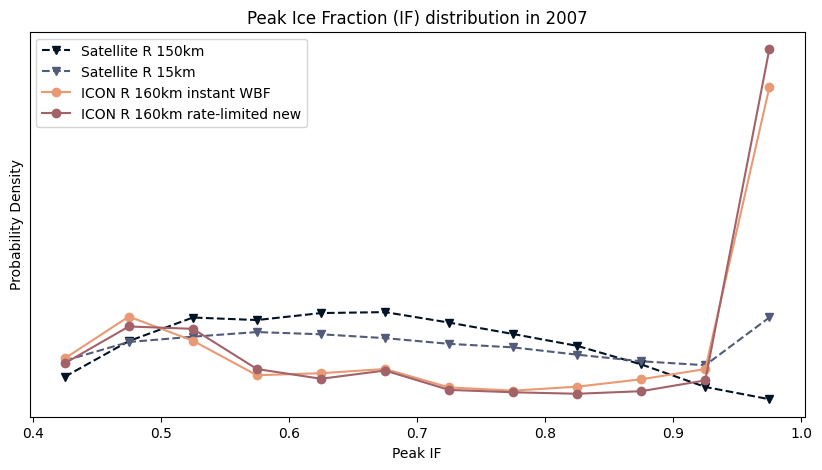

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))

# Transparent background
fig.patch.set_alpha(0)
ax.set_facecolor("none")

bins = 12

# CLAAS
counts1, edges1 = np.histogram(
    glac_low_res["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(centers1, counts1, "--v", label="Satellite R 150km", color=color_low_res)

# GLAC High Res
counts3, edges3 = np.histogram(
    glac_high_res["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(centers3, counts3, "--v", label="Satellite R 15km", color=color_high_res)

# ICON
counts2, edges2 = np.histogram(
    glac_model["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(centers2, counts2, "-o", label="ICON R 160km instant WBF", color=color_model_old_wbf)

# ICON new WBF
counts4, edges4 = np.histogram(
    glac_model_new_wbf["Peak IF"].dropna(),
    bins=bins,
    range=[0.4, 1],
    density=True
)
centers4 = 0.5 * (edges4[:-1] + edges4[1:])
ax.plot(centers4, counts4, "-o", label="ICON R 160km rate-limited new", color=color_model_new_wbf)

ax.set_title("Peak Ice Fraction (IF) distribution in 2007")
ax.set_xlabel("Peak IF")
ax.set_ylabel("Probability Density")

# Remove ticks on the vertical axis
ax.set_yticks([])
ax.tick_params(axis="y", left=False, right=False, labelleft=False)

ax.legend()

# When saving, keep background transparent too
plt.savefig("peak_if_distribution.png", transparent=True, bbox_inches="tight", dpi=300)

cmcrameri

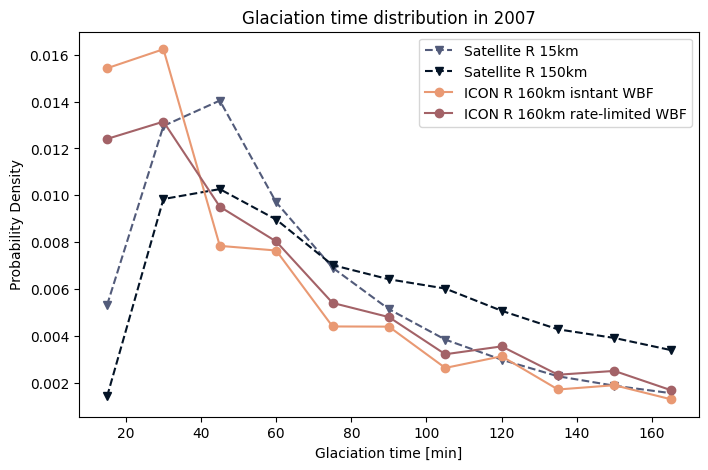

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))

bins = np.arange(7.5, 181, 15)

# Satellite R 15km
counts0, edges0 = np.histogram(
    glac_high_res["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers0 = 0.5 * (edges0[:-1] + edges0[1:])
ax.plot(centers0, counts0, "--v", label="Satellite R 15km", color=color_high_res)

# Satellite R 150km
counts1, edges1 = np.histogram(
    glac_low_res["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(centers1, counts1, "--v", label="Satellite R 150km", color=color_low_res)
# ICON R 160km
counts2, edges2 = np.histogram(
    glac_model["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(centers2, counts2, "-o", label="ICON R 160km isntant WBF", color=color_model_old_wbf)

# ICON R 160km WBF v2
counts3, edges3 = np.histogram(
    glac_model_new_wbf["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(centers3, counts3, "-o", label="ICON R 160km rate-limited WBF", color=color_model_new_wbf)

ax.set_title("Glaciation time distribution in 2007")
ax.set_xlabel("Glaciation time [min]")
ax.set_ylabel("Probability Density")
ax.legend()
plt.show()

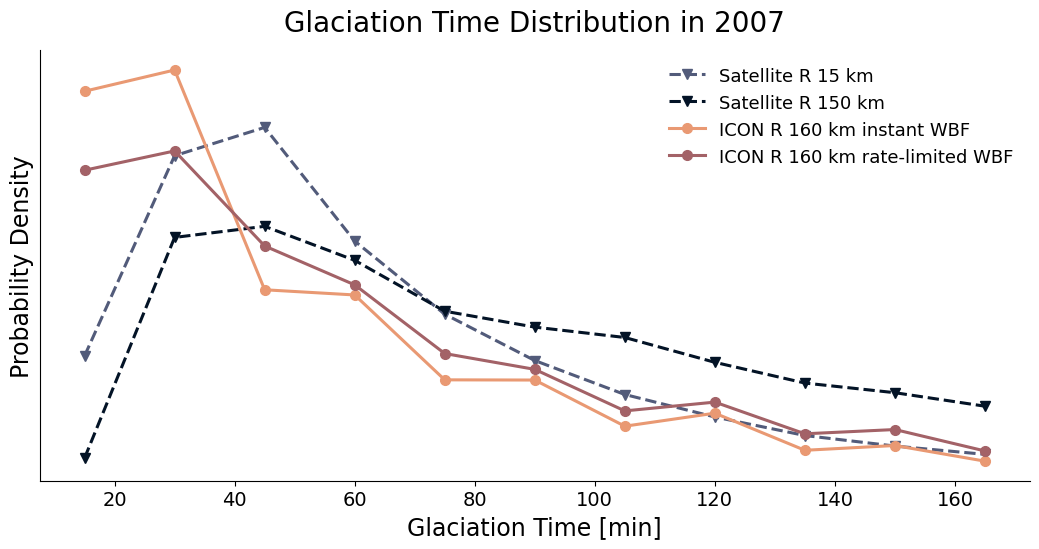

In [27]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
fig.patch.set_alpha(0)
ax.set_facecolor("none")

bins = np.arange(7.5, 181, 15)

# Satellite R 15 km
counts0, edges0 = np.histogram(
    glac_high_res["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers0 = 0.5 * (edges0[:-1] + edges0[1:])
ax.plot(
    centers0, counts0,
    "--v",
    label="Satellite R 15 km",
    color=color_high_res,
    linewidth=2.2,
    markersize=7
)

# Satellite R 150 km
counts1, edges1 = np.histogram(
    glac_low_res["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(
    centers1, counts1,
    "--v",
    label="Satellite R 150 km",
    color=color_low_res,
    linewidth=2.2,
    markersize=7
)

# ICON R 160 km instant WBF
counts2, edges2 = np.histogram(
    glac_model["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(
    centers2, counts2,
    "-o",
    label="ICON R 160 km instant WBF",
    color=color_model_old_wbf,
    linewidth=2.2,
    markersize=7
)

# ICON R 160 km rate-limited WBF
counts3, edges3 = np.histogram(
    glac_model_new_wbf["Time [m]"].dropna(),
    bins=bins,
    density=True
)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(
    centers3, counts3,
    "-o",
    label="ICON R 160 km rate-limited WBF",
    color=color_model_new_wbf,
    linewidth=2.2,
    markersize=7
)

ax.set_title(
    "Glaciation Time Distribution in 2007",
    fontsize=20,
    pad=14
)

ax.set_xlabel("Glaciation Time [min]", fontsize=17)
ax.set_ylabel("Probability Density", fontsize=17)

# X-axis tick size
ax.tick_params(axis="x", labelsize=14)

# Remove vertical-axis ticks
ax.set_yticks([])
ax.tick_params(axis="y", left=False, right=False, labelleft=False)

# Legend
ax.legend(
    fontsize=13,
    frameon=False,
    loc="best"
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Cleaner spacing
plt.tight_layout()

plt.savefig(
    "glaciation_time_distribution.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300
)

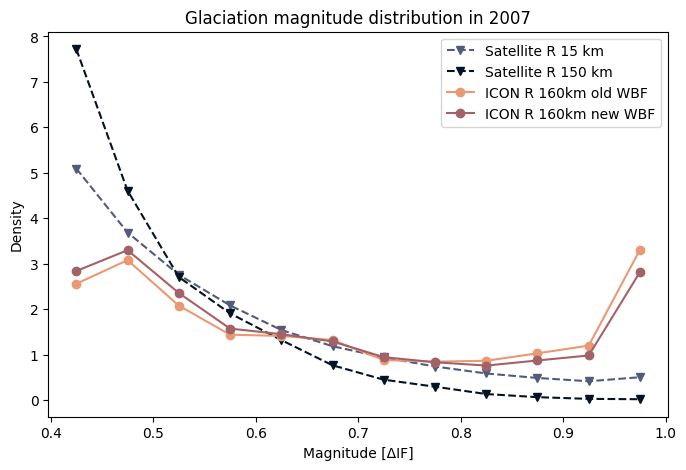

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))

bins = np.linspace(0.4, 1.0, 13)  # 12 bins from 0.4 to 1.0

# Satellite R 15km
counts0, edges0 = np.histogram(
    glac_high_res["Magnitude"].dropna(),
    bins=bins,
    density=True
)
centers0 = 0.5 * (edges0[:-1] + edges0[1:])
ax.plot(centers0, counts0, "--v", label="Satellite R 15 km", color=color_high_res)

# Satellite R 150km
counts1, edges1 = np.histogram(
    glac_low_res["Magnitude"].dropna(),
    bins=bins,
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(centers1, counts1, "--v", label="Satellite R 150 km", color=color_low_res)

# ICON R 160km old WBF
counts2, edges2 = np.histogram(
    glac_model["Magnitude"].dropna(),
    bins=bins,
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(centers2, counts2, "-o", label="ICON R 160km old WBF", color=color_model_old_wbf)

# ICON R 160km new WBF
counts3, edges3 = np.histogram(
    glac_model_new_wbf["Magnitude"].dropna(),
    bins=bins,
    density=True
)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(centers3, counts3, "-o", label="ICON R 160km new WBF", color=color_model_new_wbf)

ax.set_title("Glaciation magnitude distribution in 2007")
ax.set_xlabel("Magnitude [ΔIF]")
ax.set_ylabel("Density")
ax.legend()

plt.show()

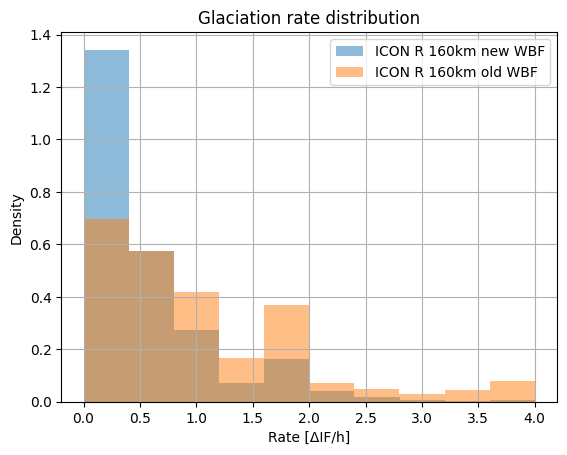

In [21]:
# (glac_low_res["Magnitude"]/(glac_low_res["Time [m]"]/60)).hist( alpha=0.5, density=True,label="Satellite R 150km")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 160km")
# (glac_model_offline["Magnitude"]/(glac_model_offline["Time [m]"]/15)).hist( alpha=0.5, density=True,label="ICON Old WBF R 160km")
(glac_model_new_wbf["Magnitude"]/(glac_model_new_wbf["Time [m]"]/60)).hist( alpha=0.5, density=True,label="ICON R 160km new WBF")
(glac_model["Magnitude"]/(glac_model["Time [m]"]/60)).hist( alpha=0.5, density=True,label="ICON R 160km old WBF")

plt.title("Glaciation rate distribution")
plt.xlabel("Rate [ΔIF/h]")
plt.ylabel("Density")
plt.legend()


In [22]:
print(glac_low_res.track_length.median())
print(glac_low_res["Time [m]"].median())
print(glac_low_res["Time [m]"].std())

0 days 03:30:00
105.0
139.8754731634525


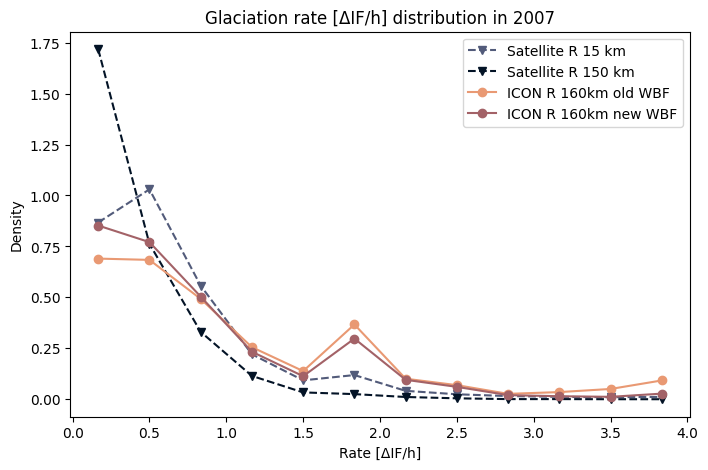

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))

# Adjust bin range if needed after seeing your data
bins = np.linspace(0, 4.0, 13)  # 12 bins

# Satellite R 15 km
rate0 = glac_high_res["Magnitude"] / (glac_high_res["Time [m]"] / 60)
counts0, edges0 = np.histogram(
    rate0.dropna(),
    bins=bins,
    density=True
)
centers0 = 0.5 * (edges0[:-1] + edges0[1:])
ax.plot(centers0, counts0, "--v", label="Satellite R 15 km", color=color_high_res)

# Satellite R 150 km
rate1 = glac_low_res["Magnitude"] / (glac_low_res["Time [m]"] / 60)
counts1, edges1 = np.histogram(
    rate1.dropna(),
    bins=bins,
    density=True
)
centers1 = 0.5 * (edges1[:-1] + edges1[1:])
ax.plot(centers1, counts1, "--v", label="Satellite R 150 km", color=color_low_res)

# ICON R 160km old WBF
rate2 = glac_model["Magnitude"] / (glac_model["Time [m]"] / 60)
counts2, edges2 = np.histogram(
    rate2.dropna(),
    bins=bins,
    density=True
)
centers2 = 0.5 * (edges2[:-1] + edges2[1:])
ax.plot(centers2, counts2, "-o", label="ICON R 160km old WBF", color=color_model_old_wbf)

# ICON R 160km new WBF
rate3 = glac_model_new_wbf["Magnitude"] / (glac_model_new_wbf["Time [m]"] / 60)
counts3, edges3 = np.histogram(
    rate3.dropna(),
    bins=bins,
    density=True
)
centers3 = 0.5 * (edges3[:-1] + edges3[1:])
ax.plot(centers3, counts3, "-o", label="ICON R 160km new WBF", color=color_model_new_wbf)

ax.set_title("Glaciation rate [ΔIF/h] distribution in 2007")
ax.set_xlabel("Rate [ΔIF/h]")
ax.set_ylabel("Density")
ax.legend()

plt.show()

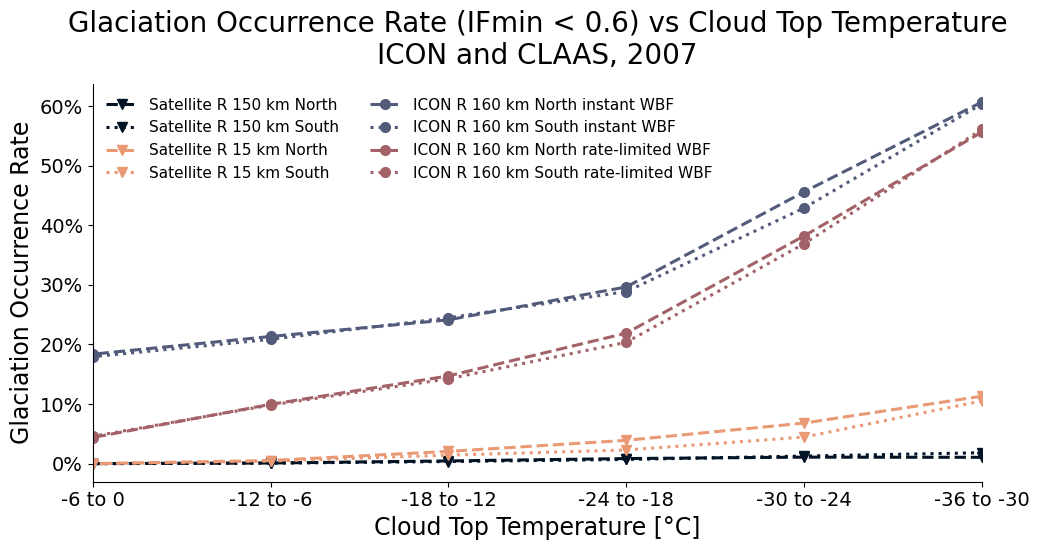

In [47]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(10.5, 5.6))

# Transparent background
fig.patch.set_alpha(0)
ax.set_facecolor("none")

high_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_high_res, None, None))
low_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_low_res, None, None))
model_online_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_model, None, None))
model_new_wbf_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_model_new_wbf, None, None))

# CLAAS / Satellite R 150 km
ax.plot(
    low_res_occ_rate.columns,
    low_res_occ_rate.loc["North"],
    label="Satellite R 150 km North",
    color=colormap(0),
    linestyle="dashed",
    marker="v",
    linewidth=2.2,
    markersize=7
)
ax.plot(
    low_res_occ_rate.columns,
    low_res_occ_rate.loc["South"],
    label="Satellite R 150 km South",
    color=colormap(0),
    linestyle="dotted",
    marker="v",
    linewidth=2.2,
    markersize=7
)

# CLAAS / Satellite R 15 km
ax.plot(
    high_res_occ_rate.columns,
    high_res_occ_rate.loc["North"],
    label="Satellite R 15 km North",
    color=colormap(3),
    linestyle="dashed",
    marker="v",
    linewidth=2.2,
    markersize=7
)
ax.plot(
    high_res_occ_rate.columns,
    high_res_occ_rate.loc["South"],
    label="Satellite R 15 km South",
    color=colormap(3),
    linestyle="dotted",
    marker="v",
    linewidth=2.2,
    markersize=7
)

# ICON old WBF
ax.plot(
    model_online_occ_rate.columns,
    model_online_occ_rate.loc["North"],
    label="ICON R 160 km North instant WBF",
    color=colormap(4),
    linestyle="dashed",
    marker="o",
    linewidth=2.2,
    markersize=7
)
ax.plot(
    model_online_occ_rate.columns,
    model_online_occ_rate.loc["South"],
    label="ICON R 160 km South instant WBF",
    color=colormap(4),
    linestyle="dotted",
    marker="o",
    linewidth=2.2,
    markersize=7
)

# ICON new WBF
ax.plot(
    model_new_wbf_occ_rate.columns,
    model_new_wbf_occ_rate.loc["North"],
    label="ICON R 160 km North rate-limited WBF",
    color=colormap(2),
    linestyle="dashed",
    marker="o",
    linewidth=2.2,
    markersize=7
)
ax.plot(
    model_new_wbf_occ_rate.columns,
    model_new_wbf_occ_rate.loc["South"],
    label="ICON R 160 km South rate-limited WBF",
    color=colormap(2),
    linestyle="dotted",
    marker="o",
    linewidth=2.2,
    markersize=7
)

# Axis limits and direction
ax.set_xlim(-36, -6)
ax.invert_xaxis()

# Title and labels
ax.set_title(
    "Glaciation Occurrence Rate (IFmin < 0.6) vs Cloud Top Temperature\nICON and CLAAS, 2007",
    fontsize=20,
    pad=14
)
ax.set_xlabel("Cloud Top Temperature [°C]", fontsize=17)
ax.set_ylabel("Glaciation Occurrence Rate", fontsize=17)

# Tick formatting
ax.tick_params(axis="x", labelsize=14)
ax.tick_params(axis="y", labelsize=14)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

ax.set_xticks(
    np.arange(-36, -6 + 1, 6),
    labels=[f"{i} to {i+6}" for i in range(-36, 0, 6)]
)

# Remove top and right axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend
ax.legend(
    fontsize=11,
    frameon=False,
    loc="upper left",
    ncol=2
)

# Cleaner spacing
plt.tight_layout()

plt.savefig(
    "glaciation_occurrence_rate_vs_ctt.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300
)

/cluster/work/climate/dnikolo/dump/ipykernel_2599806/1079521368.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])


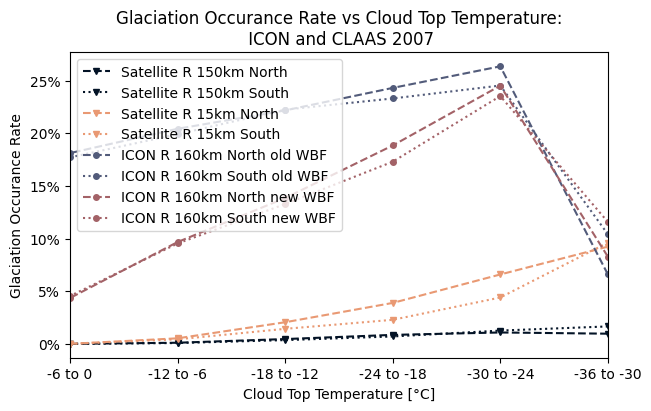

In [48]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
high_res_occ_rate = calculate_pole_temp_occurance_rate((clouds_high_res,None,None))
low_res_occ_rate = calculate_pole_temp_occurance_rate((clouds_low_res,None,None))
# model_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_offline,None,None))
model_online_occ_rate = calculate_pole_temp_occurance_rate((clouds_model,None,None))
model_new_wbf_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_new_wbf ,None,None))


ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['North'],label='Satellite R 150km North',color=colormap(0),linestyle='dashed',marker='v',markersize=4)
ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['South'],label='Satellite R 150km South',color=colormap(0),linestyle='dotted',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['North'],label='Satellite R 15km North',color = colormap(3),linestyle='dashed',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['South'],label='Satellite R 15km South',color = colormap(3),linestyle='dotted',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['North'],label='ICON Old WBF R 160km North',color=colormap(2),linestyle='dashed',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['South'],label='ICON Old WBF R 160km South',color=colormap(2),linestyle='dotted',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['North'],label='ICON R 160km North old WBF',color=colormap(4),linestyle='dashed',marker='o',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['South'],label='ICON R 160km South old WBF',color=colormap(4),linestyle='dotted',marker='o',markersize=4)
ax.plot(model_new_wbf_occ_rate.columns,model_new_wbf_occ_rate.loc['North'],label='ICON R 160km North new WBF',color=colormap(2),linestyle='dashed',marker='o',markersize=4)
ax.plot(model_new_wbf_occ_rate.columns,model_new_wbf_occ_rate.loc['South'],label='ICON R 160km South new WBF',color=colormap(2),linestyle='dotted',marker='o',markersize=4)


ax.set_xlim(-36,-6)

ax.invert_xaxis()
vals = ax.get_yticks()
ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
ax.set_ylabel('Glaciation Occurance Rate')
ax.legend(loc="upper left")
ax.set_xlabel('Cloud Top Temperature [°C]')
ax.set_xticks(np.arange(-36,-6+1,6),labels=[f"{i} to {i+6}" for i in range(-36,0,6)])
ax.set_title('Glaciation Occurance Rate vs Cloud Top Temperature:\n ICON and CLAAS 2007')
fig.savefig("/nfs/ch4/wolke_scratch/dnikolo/MSGI/figures/model_vs_CLAAS_occ_rate.png",dpi=300)

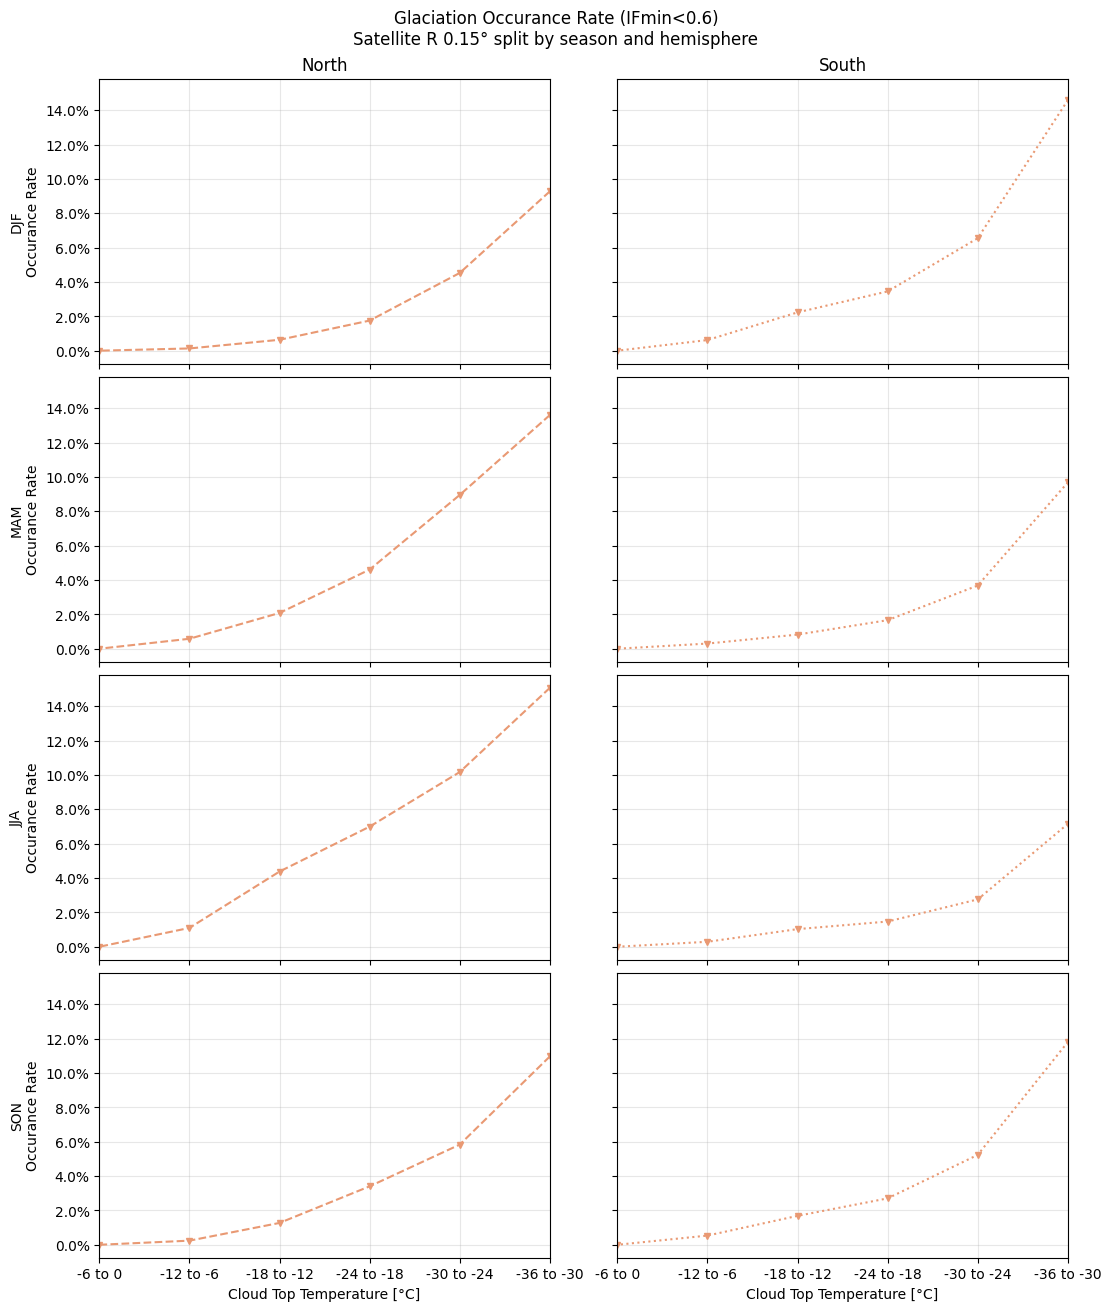

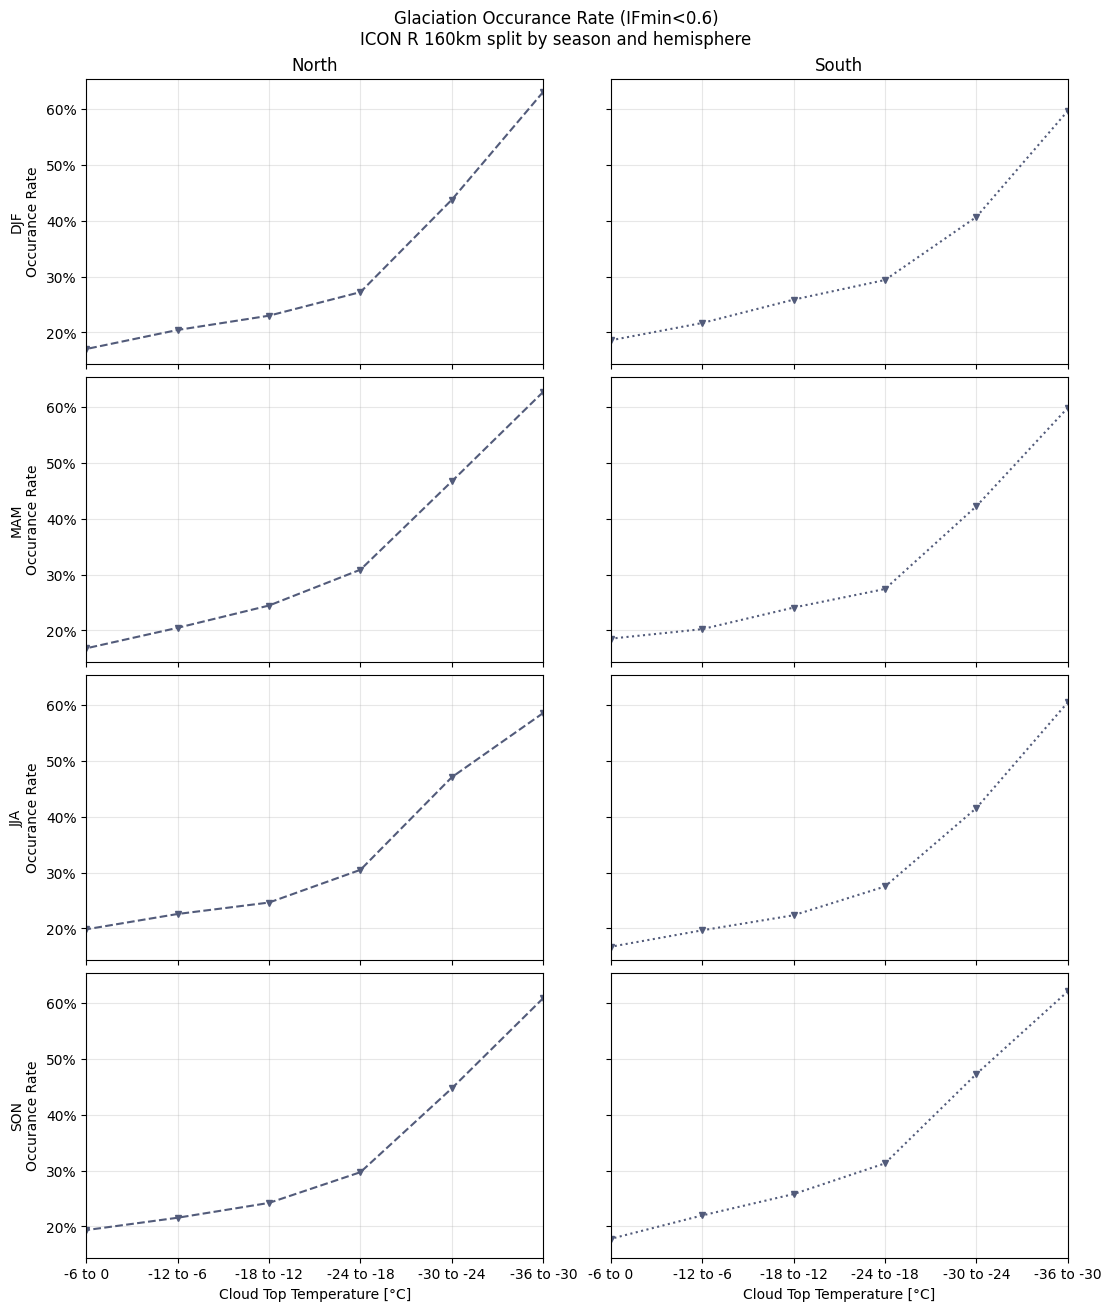

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]

def get_month_mask_from_time(clouds, months, time_name="track_start_time"):
    """
    Return boolean mask selecting entries whose `time_name` month is in `months`.

    Works for xarray objects and pandas-like tables as long as
    `clouds[time_name]` exists and is datetime-like.
    """
    time = clouds[time_name]

    # xarray / numpy datetime compatible
    try:
        return time.dt.month.isin(months)
    except Exception:
        # fallback for pandas-like objects
        time = pd.to_datetime(time)
        return time.dt.month.isin(months)


def subset_clouds_by_season(clouds, season, time_name="track_start_time"):
    """
    Subset cloud dataset by meteorological season using track_start_time.
    Assumes clouds is either:
      - xarray Dataset/DataArray with dimension 'track'
      - pandas DataFrame/Series-like object with boolean indexing
    """
    season_to_months = {
        "DJF": [12, 1, 2],
        "MAM": [3, 4, 5],
        "JJA": [6, 7, 8],
        "SON": [9, 10, 11],
    }

    months = season_to_months[season]
    mask = get_month_mask_from_time(clouds, months, time_name=time_name)

    # xarray-style
    try:
        return clouds.sel(track=mask)
    except Exception:
        pass

    try:
        return clouds.isel(track=mask)
    except Exception:
        pass

    # pandas-style fallback
    return clouds[mask]


def calc_occ_rate_for_seasons(clouds, time_name="track_start_time"):
    """
    Returns dict: season -> occurrence rate DataFrame
    """
    out = {}
    for season in SEASON_ORDER:
        clouds_season = subset_clouds_by_season(clouds, season, time_name=time_name)
        out[season] = calculate_pole_temp_occurance_rate_glac_possible((clouds_season, None, None))
    return out


def plot_seasonal_occurrence_grid(
    seasonal_occ_dict,
    dataset_label,
    color,
    outpath,
    title_prefix="Glaciation Occurance Rate (IFmin<0.6)"
):
    """
    Plot 4 rows (seasons) x 2 cols (North/South) for one dataset.
    """
    hemispheres = ["North", "South"]

    fig, axes = plt.subplots(
        nrows=4, ncols=2,
        figsize=(11, 13),
        sharex=True, sharey=True,
        layout="constrained"
    )

    for i, season in enumerate(SEASON_ORDER):
        occ_rate = seasonal_occ_dict[season]

        for j, hemi in enumerate(hemispheres):
            ax = axes[i, j]

            ax.plot(
                occ_rate.columns,
                occ_rate.loc[hemi],
                color=color,
                linestyle="dashed" if hemi == "North" else "dotted",
                marker="v",
                markersize=4,
                label=f"{dataset_label} {hemi}"
            )

            ax.set_xlim(-36, -6)
            ax.invert_xaxis()
            ax.set_xticks(
                np.arange(-36, -6 + 1, 6),
                labels=[f"{i} to {i+6}" for i in range(-36, 0, 6)]
            )
            ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
            ax.grid(alpha=0.3)

            if i == 0:
                ax.set_title(hemi)

            if j == 0:
                ax.set_ylabel(f"{season}\nOccurance Rate")

            if i == len(SEASON_ORDER) - 1:
                ax.set_xlabel("Cloud Top Temperature [°C]")

    fig.suptitle(f"{title_prefix}\n{dataset_label} split by season and hemisphere")
    # fig.savefig(outpath, dpi=300)
    # plt.close(fig)


# ------------------------------------------------------------
# Compute seasonal occurrence rates
# ------------------------------------------------------------
high_res_occ_by_season = calc_occ_rate_for_seasons(
    clouds_high_res,
    time_name="track_start_time"
)

model_occ_by_season = calc_occ_rate_for_seasons(
    clouds_model,
    time_name="track_start_time"
)

# ------------------------------------------------------------
# Plot each dataset separately
# ------------------------------------------------------------
plot_seasonal_occurrence_grid(
    seasonal_occ_dict=high_res_occ_by_season,
    dataset_label="Satellite R 0.15°",
    color=colormap(3),
    outpath="/nfs/ch4/wolke_scratch/dnikolo/MSGI/figures/CLAAS_highres_occ_rate_seasonal_by_pole.png"
)

plot_seasonal_occurrence_grid(
    seasonal_occ_dict=model_occ_by_season,
    dataset_label="ICON R 160km",
    color=colormap(4),
    outpath="/nfs/ch4/wolke_scratch/dnikolo/MSGI/figures/ICON_model_occ_rate_seasonal_by_pole.png"
)

/cluster/work/climate/dnikolo/dump/ipykernel_2599806/3981949667.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])


FileNotFoundError: [Errno 2] No such file or directory: '/wolke_scratch/dnikolo/MSGI/figures/model_vs_CLAAS_occ_rate.png'

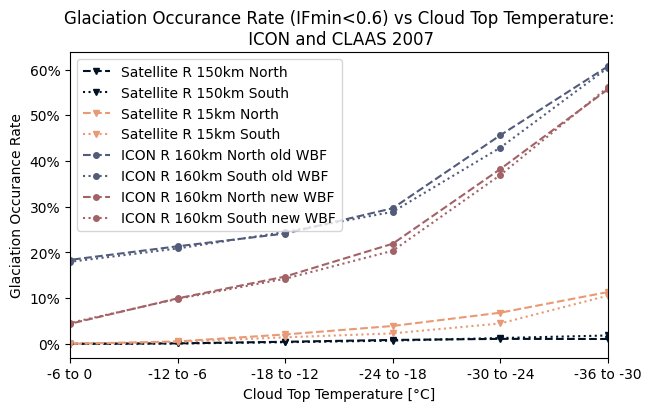

In [50]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
high_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_high_res,None,None))
low_res_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_low_res,None,None))
# model_occ_rate = calculate_pole_temp_occurance_rate((clouds_model_offline,None,None))
model_online_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_model,None,None))
model_new_wbf_occ_rate = calculate_pole_temp_occurance_rate_glac_possible((clouds_model_new_wbf ,None,None))

ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['North'],label='Satellite R 150km North',color=colormap(0),linestyle='dashed',marker='v',markersize=4)
ax.plot(low_res_occ_rate.columns,low_res_occ_rate.loc['South'],label='Satellite R 150km South',color=colormap(0),linestyle='dotted',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['North'],label='Satellite R 15km North',color = colormap(3),linestyle='dashed',marker='v',markersize=4)
ax.plot(high_res_occ_rate.columns,high_res_occ_rate.loc['South'],label='Satellite R 15km South',color = colormap(3),linestyle='dotted',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['North'],label='ICON Old WBF R 160km North',color=colormap(2),linestyle='dashed',marker='v',markersize=4)
# ax.plot(model_occ_rate.columns,model_occ_rate.loc['South'],label='ICON Old WBF R 160km South',color=colormap(2),linestyle='dotted',marker='v',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['North'],label='ICON R 160km North old WBF',color=colormap(4),linestyle='dashed',marker='o',markersize=4)
ax.plot(model_online_occ_rate.columns,model_online_occ_rate.loc['South'],label='ICON R 160km South old WBF',color=colormap(4),linestyle='dotted',marker='o',markersize=4)
ax.plot(model_new_wbf_occ_rate.columns,model_new_wbf_occ_rate.loc['North'],label='ICON R 160km North new WBF',color=colormap(2),linestyle='dashed',marker='o',markersize=4)
ax.plot(model_new_wbf_occ_rate.columns,model_new_wbf_occ_rate.loc['South'],label='ICON R 160km South new WBF',color=colormap(2),linestyle='dotted',marker='o',markersize=4)

ax.set_xlim(-36,-6)

ax.invert_xaxis()
vals = ax.get_yticks()
ax.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
ax.set_ylabel('Glaciation Occurance Rate')
ax.legend(loc="upper left")
ax.set_xlabel('Cloud Top Temperature [°C]')
ax.set_xticks(np.arange(-36,-6+1,6),labels=[f"{i} to {i+6}" for i in range(-36,0,6)])
ax.set_title('Glaciation Occurance Rate (IFmin<0.6) vs Cloud Top Temperature:\n ICON and CLAAS 2007')
fig.savefig("/wolke_scratch/dnikolo/MSGI/figures/model_vs_CLAAS_occ_rate.png",dpi=300)

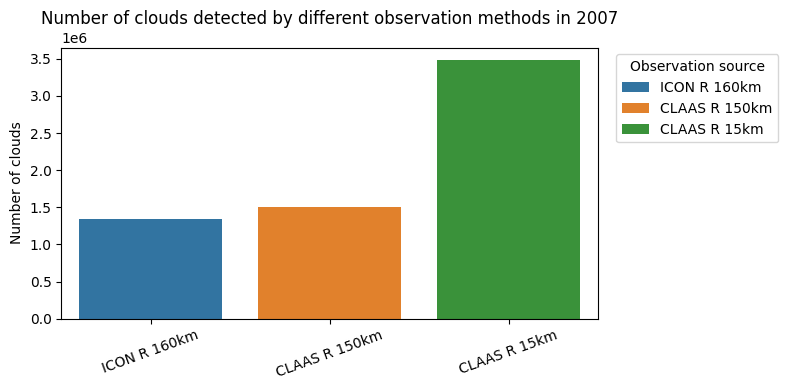

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Count rows in each dataframe
counts = pd.DataFrame({
    "Observation method": [
        "ICON R 160km",
        "Satellite R 150km",
        "Satellite R 15km",  
    ],
    "Num clouds (rows)": [
        len(clouds_model),
        len(clouds_low_res),
        len(clouds_high_res),
        
    ]
})

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    data=counts,
    x="Observation method",
    y="Num clouds (rows)",
    hue="Observation method",      # makes a legend
    dodge=False
)

ax.set_xlabel("")
ax.set_ylabel("Number of clouds")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Observation source", bbox_to_anchor=(1.02, 1), loc="upper left")

# (optional) add value labels on bars
# for container in ax.containers:
#     ax.bar_label(container, fmt="%.0f", padding=3)
ax.set_title("Number of clouds detected by different observation methods in 2007")
plt.tight_layout()
plt.show()


In [ ]:
import seaborn as sns

In [ ]:
fig,ax = plt.subplots(1, 1, figsize=(6.4,  4), layout="constrained")
sns.histplot(clouds_model[clouds_model["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="ICON R 160km" )
sns.histplot(clouds_high_res[clouds_high_res["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="Satellite R 15km")
sns.histplot(clouds_low_res[clouds_low_res["avg_size[km]"]<1e5]["avg_size[km]"], log_scale=(False, True), bins=20,ax= ax,label="Satellite R 150km")
ax.set_title('Cloud top area distribution \n for different observation methods in 2007')
plt.legend()
ax.set_xlabel('Cloud top area [km^2]')

Text(0.5, 0, 'Cloud top area [km^2]')

Error in callback <function flush_figures at 0x7feebab2ccc0> (for post_execute):


KeyboardInterrupt: 

In [ ]:
(clouds_high_res["avg_size[km]"]<0.01e7).value_counts(normalize=True)

avg_size[km]
True     0.997858
False    0.002142
Name: proportion, dtype: float64

# Calculations

In [ ]:
(glac_model.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.927476
True     0.072524
Name: proportion, dtype: float64

In [ ]:
(glac_model_new_wbf.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.9605
True     0.0395
Name: proportion, dtype: float64

In [ ]:
(glac_low_res.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.996839
True     0.003161
Name: proportion, dtype: float64

In [ ]:
(glac_high_res.Cloud_ID.value_counts()>1).value_counts(normalize=True)

count
False    0.992448
True     0.007552
Name: proportion, dtype: float64

In [ ]:
from scipy.signal import savgol_filter

def noise_filter_4(row, w=4, order=2):
    IF_hist = np.array(row['ice_frac_hist'])
    return savgol_filter(IF_hist, w, order)

In [ ]:
se_sum=0
sample_count=0
for i, row in glac_high_res.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.0651292202357399


In [ ]:
se_sum=0
sample_count=0
for i, row in glac_model.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

0.09630264845824899


In [ ]:
se_sum=0
sample_count=0
for i, row in glac_model.iterrows():
    data = np.array(row['ice_frac_hist'])
    filt_data = noise_filter_4(row)
    # filt_data = savgol_filter(data, window_length=5, polyorder=2)
    first_estimate=0.1
    meas_idx = (data<1-first_estimate) & (data>first_estimate)
    se_sum += (np.square(data[meas_idx] - filt_data[meas_idx])).sum()
    sample_count+=len(data[meas_idx])
print(np.sqrt(se_sum/sample_count))

In [ ]:
(glac_low_res["Time [m]"]==15).value_counts()

Time [m]
False    1396
True       85
Name: count, dtype: int64

## Deprecated

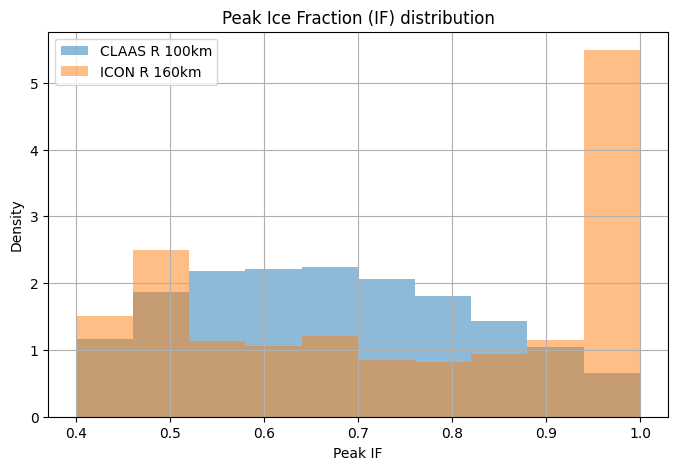

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
glac_low_res["Peak IF"].hist( alpha=0.5, density=True,label="Satellite R 150km")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON Old WBF R 160km")
glac_model["Peak IF"].hist( alpha=0.5, density=True,label="ICON R 160km")
plt.title("Peak Ice Fraction (IF) distribution")
plt.xlabel("Peak IF")
plt.ylabel("Density")
plt.legend()

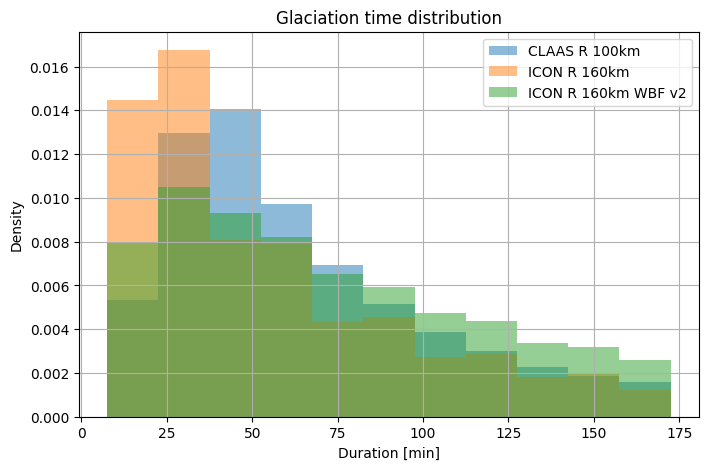

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
# glac_low_res["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="Satellite R 150km")
# glac_model_offline["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON Old WBF R 160km")
glac_high_res["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="Satellite R 150km")
glac_model["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 160km")
glac_model_new_wbf["Time [m]"].hist(bins=np.arange(7.5,181,15), alpha=0.5, density=True,label="ICON R 160km WBF v2")
# glac_model["Time [m]"].hist( alpha=0.5, density=True,label="ICON R 160km")
plt.title("Glaciation time distribution")
plt.xlabel("Duration [min]")
plt.ylabel("Density")
plt.legend()